In [1]:
import sys
import numpy as np
import xarray as xr
import zarr
import dask.array as dsa

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import cartopy.crs as ccrs
import cmocean
import seaborn as sns

from functools import partial

In [2]:
sys.path.append("../..")
from regions import REGIONS as all_regions, set_region, projection, wrap_longitudes, to_grid, draw_cells

In [3]:
plt.style.use("../../nice.mplstyle")

In [5]:
DATASET = "anemoi-hpx6-24h/dataset.zarr"


def healpix_cells(n_cells, path=DATASET):
    """The parent-mesh pixel id of each stored cell.

    data.yaml prunes the mesh to its ocean cells (land_fraction < 0.1), so a stored field is
    ~33k cells long rather than the 49152 of hpx6, and nese-dataprep records which cells
    survived as ``healpix_cell_index``. Runs written before select_cells (v0-v2) still carry
    the whole mesh, and there the pixel ids are just the positions.
    """
    group = zarr.open(path, mode="r")
    index = group["healpix_cell_index"][:] if "healpix_cell_index" in group else np.arange(n_cells)
    return index if len(index) == n_cells else np.arange(n_cells)


def scatter_to_mesh(xda, path=DATASET):
    """Put a field on the stored cells back onto the full HEALPix mesh.

    ``draw_cells`` reads nside off the array length, so it needs the whole mesh. Cells that
    select_cells pruned come back NaN, which is what paints them grey. A field that is already
    on the full mesh passes through untouched.
    """
    npix = 12*zarr.open(path, mode="r").attrs["healpix_nside"]**2
    return xda.reindex(cell=np.arange(npix))

In [6]:
def open_dataset(*args, **kwargs):
    xds = xr.open_dataset(*args, **kwargs)
    xds = wrap_longitudes(xds)
    xds = xds.rename(
        {
            "values": "cell",
        }
    )
    xds["cell"] = healpix_cells(xds.sizes["cell"])
    xds["elevation"] = xds.elevation.isel(time=0, drop=True).load()
    xds["land_fraction"] = xds.land_fraction.isel(time=0, drop=True).load()
    for x in ["latitude", "longitude"]:
        xds = xds.set_coords(x)
        xds[x].load();
    xds["mask"] = xds.land_fraction < 0.1
    xds["mask"].load()
    return xds

In [7]:
from copy import deepcopy
def open_anemoi_zarr(path, array_name="data"):
    group = zarr.open(path, mode="r")
    if array_name == "data":
        da = xr.DataArray(
            dsa.from_zarr(group[array_name])[:, :, 0, :],
            dims=("time", "variable", "cell"),
            coords={
                "time": group["dates"][:],
                "variable": list(group.attrs["variables"]),
                "cell": healpix_cells(group["data"].shape[-1], path),
                "latitude": ("cell", group["latitudes"][:]),
                "longitude": ("cell", group["longitudes"][:]),
            },
        )
    else:
        da = xr.DataArray(
            dsa.from_zarr(group[array_name]),
            dims=("variable",),
            coords={
                "variable": list(group.attrs["variables"]),
            },
        )
    xds = da.to_dataset(dim="variable")
    xds.attrs = deepcopy(group.attrs)
    return xds

In [8]:
#ds = open_dataset("runs/v0/inference-validation/2015-07-02T12.nc", chunks="auto")
ds = open_dataset("runs/v3/inference-validation/2015-12-31T12.nc", chunks="auto")

In [9]:
def plot(region, varnames=("sla_filtered_jason_2", "sla_filtered_cryosat_2", "sla"), **kwargs):
    nrows = 1
    ncols = len(varnames)
    
    fig, axs = plt.subplots(
        nrows=nrows,
        ncols=ncols,
        figsize=(5*ncols, 4*nrows),
        subplot_kw={"projection": projection(region)},
    )
    
    s = kwargs.pop("s", 5)
    cmap = kwargs.pop("cmap", "cmo.balance")
    vmin = kwargs.pop("vmin", None)
    vmax = kwargs.pop("vmax", None)
    if vmin is None and vmax is None:
        vmax = .8*np.abs(ds["sla"].isel(time=1)).max().values
        vmin = -vmax
        
    for varname, ax in zip(varnames, axs):
        itime = 0 if "filtered" in varname else 1
        ax.scatter(
            ds.longitude,
            ds.latitude,
            c=ds[varname].isel(time=itime).values,#.where(ds.mask).values,
            cmap=cmap,
            vmin=vmin,
            vmax=vmax,
            transform=ccrs.PlateCarree(),
            s=s,
            **kwargs,
        )
        ax.set(title=varname)
        set_region(ax, region)
    return fig, axs

In [10]:
def hplot(region, varnames=("sla_filtered_jason_2", "sla_filtered_cryosat_2", "sla"), **kwargs):
    nrows = 1
    ncols = len(varnames)
    
    fig, axs = plt.subplots(
        nrows=nrows,
        ncols=ncols,
        figsize=(5*ncols, 4*nrows),
        subplot_kw={"projection": projection(region)},
    )
    
    s = kwargs.pop("s", 5)
    cmap = kwargs.pop("cmap", "cmo.balance")
    vmin = kwargs.pop("vmin", None)
    vmax = kwargs.pop("vmax", None)
    if vmin is None and vmax is None:
        vmax = .8*np.abs(ds["sla"].isel(time=1)).max().values
        vmin = -vmax

    for varname, ax in zip(varnames, axs):
        itime = 0 if "filtered" in varname else 1
        set_region(ax, region)
        plotme = scatter_to_mesh(ds[varname].isel(time=itime))
        #lon, lat, plotme = to_grid(plotme, region=region)
        #ax.pcolormesh(lon, lat, plotme, vmin=vmin, vmax=vmax, cmap=cmap, transform=ccrs.PlateCarree(), **kwargs)
        # Something is wrong with NaNs
        cc = draw_cells(ax, plotme, vmin=vmin, vmax=vmax, cmap=cmap, **kwargs)
        ax.set(title=varname)
    return fig, axs

In [11]:
all_regions.keys()

dict_keys(['global', 'north_atlantic', 'subpolar_gyre', 'gulf_stream', 'labrador_sea', 'nordic_seas', 'tropical_pacific', 'kuroshio', 'agulhas', 'southern_ocean', 'mediterranean', 'europe'])

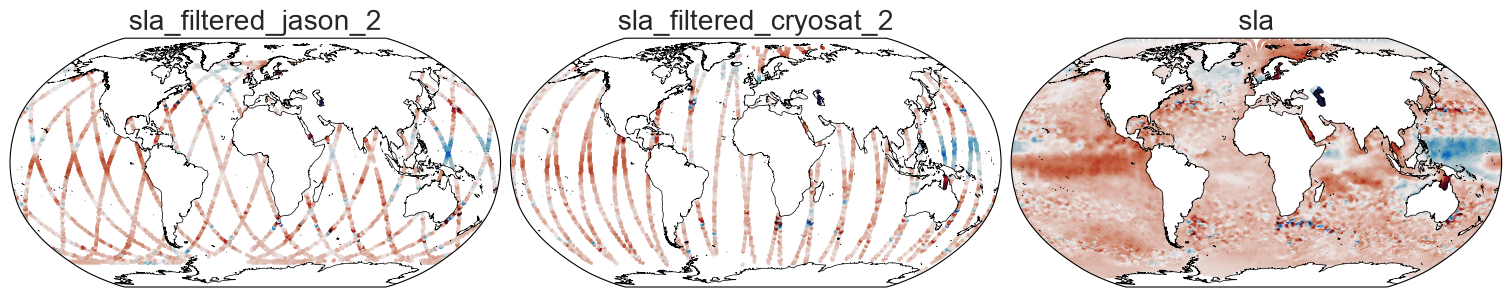

In [12]:
plot("global");

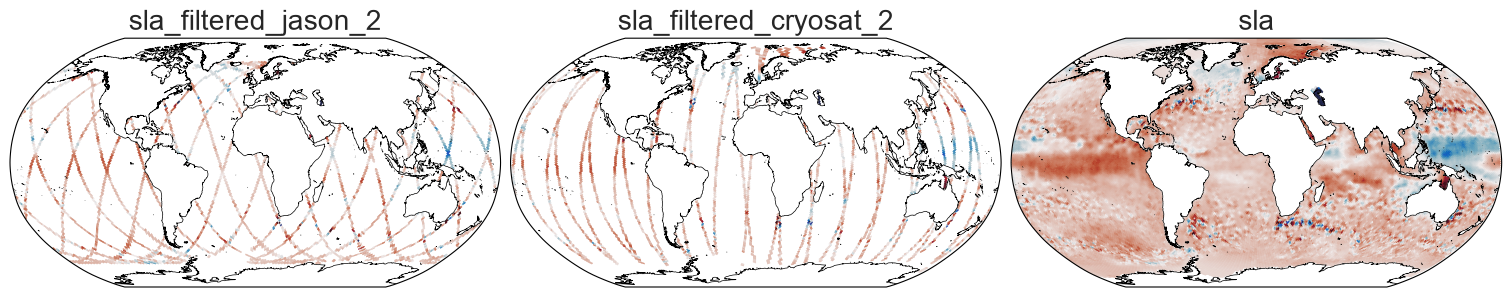

In [13]:
hplot("global");

(<Figure size 1500x400 with 3 Axes>,
 array([<GeoAxes: title={'center': 'sla_filtered_jason_2'}>,
        <GeoAxes: title={'center': 'sla_filtered_cryosat_2'}>,
        <GeoAxes: title={'center': 'sla'}>], dtype=object))

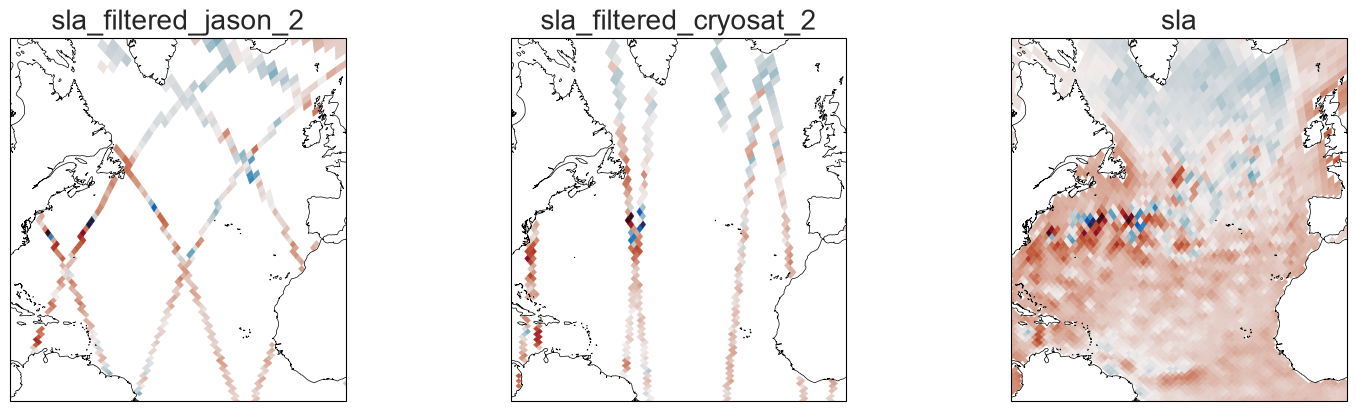

In [14]:
hplot("north_atlantic")

(<Figure size 1500x400 with 3 Axes>,
 array([<GeoAxes: title={'center': 'sla_filtered_jason_2'}>,
        <GeoAxes: title={'center': 'sla_filtered_cryosat_2'}>,
        <GeoAxes: title={'center': 'sla'}>], dtype=object))

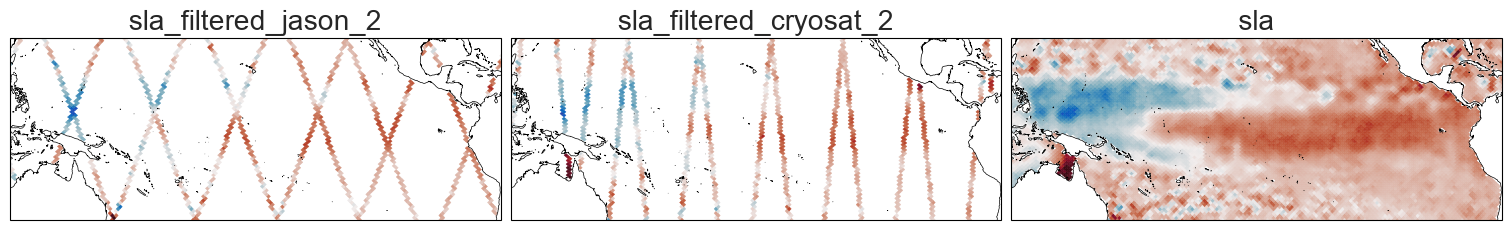

In [15]:
hplot("tropical_pacific")

In [ ]:
nrows = 1

varnames = [
    "sla_filtered_jason_2",
    "sla_filtered_cryosat_2",
    "sla",
]
ncols = len(varnames)

fig, axs = plt.subplots(nrows, ncols, figsize=(5*ncols, 4*nrows), subplot_kw={"projection": ccrs.Robinson()})

for varname, ax in zip(varnames, axs):
    itime = 0 if "filtered" in varname else 1
    ax.scatter(
        ds.longitude,
        ds.latitude,
        c=ds[varname].isel(time=itime).values,#.where(ds.mask).values,
        cmap="cmo.balance",
        vmin=-.1,
        vmax=.1,
        transform=ccrs.PlateCarree(),
        s=5,
    )
    ax.set(title=varname)
    ax.set_extent([

In [24]:
ads = open_anemoi_zarr("anemoi-hpx6-24h/dataset.zarr")

missions = [x for x in ds.data_vars if "sla_filtered" in x]

In [29]:
init_time, valid_time = ds.time.values
input_times = [init_time - n*np.timedelta64(24, "h") for n in [2, 1, 0]]

inputs = ads[missions].sel(time=input_times).compute()
inputs

<xarray.Dataset> Size: 9MB
Dimensions:                                  (time: 3, cell: 49152)
Coordinates:
  * time                                     (time) datetime64[s] 24B 2015-06...
  * cell                                     (cell) int64 393kB 0 1 ... 49151
    latitude                                 (cell) float64 393kB 0.5968 ... ...
    longitude                                (cell) float64 393kB 45.0 ... 315.0
Data variables: (12/13)
    sla_filtered_cryosat_2                   (time, cell) float32 590kB nan ....
    sla_filtered_envisat                     (time, cell) float32 590kB nan ....
    sla_filtered_envisat_new_orbit           (time, cell) float32 590kB nan ....
    sla_filtered_ers_2                       (time, cell) float32 590kB nan ....
    sla_filtered_gfo                         (time, cell) float32 590kB nan ....
    sla_filtered_haiyang_2a                  (time, cell) float32 590kB nan ....
    ...                                       ...
    sla_filtered_jason_1_geodetic            (time, cell) float32 590kB nan ....
    sla_filtered_jason_1_interleaved         (time, cell) float32 590kB nan ....
    sla_filtered_jason_2                     (time, cell) float32 590kB nan ....
    sla_filtered_saral                       (time, cell) float32 590kB nan ....
    sla_filtered_topex_poseidon              (time, cell) float32 590kB nan ....
    sla_filtered_topex_poseidon_interleaved  (time, cell) float32 590kB nan ....
Attributes: (12/24)
    allow_nans:              True
    binned:                  True
    constant_fields:         []
    end_date:                2015-12-31T12:00:00
    ensemble_dimension:      1
    field_shape:             [49152]
    ...                      ...
    statistics_end_date:     2014-12-31T12:00:00
    statistics_start_date:   2000-01-01T12:00:00
    time_bin_closed:         left
    time_bin_label:          middle
    variables:               ['sla_filtered_cryosat_2', 'sla_filtered_envisat...
    variables_metadata:      {'sla_filtered_cryosat_2': {'group': 'cryosat_2'...

In [30]:
for varname in missions:
    same = np.array_equal(
        inputs[varname].sel(time=init_time).values,
        ds[varname].isel(time=0).values,
        equal_nan=True,
    )
    print(f"{varname}: matches inference file = {same}")

sla_filtered_cryosat_2: matches inference file = True
sla_filtered_envisat: matches inference file = True
sla_filtered_envisat_new_orbit: matches inference file = True
sla_filtered_ers_2: matches inference file = True
sla_filtered_gfo: matches inference file = True
sla_filtered_haiyang_2a: matches inference file = True
sla_filtered_jason_1: matches inference file = True
sla_filtered_jason_1_geodetic: matches inference file = True
sla_filtered_jason_1_interleaved: matches inference file = True
sla_filtered_jason_2: matches inference file = True
sla_filtered_saral: matches inference file = True
sla_filtered_topex_poseidon: matches inference file = True
sla_filtered_topex_poseidon_interleaved: matches inference file = True


In [32]:
has_obs = inputs.notnull().any("time")
has_obs["any_mission"] = has_obs.to_dataarray(dim="variable").any("variable")

for varname in has_obs.data_vars:
    n_observed = int(has_obs[varname].sum())
    if n_observed > 0:
        print(f"{varname}: {n_observed} cells observed")

sla_filtered_cryosat_2: 9294 cells observed
sla_filtered_haiyang_2a: 5630 cells observed
sla_filtered_jason_2: 10223 cells observed
any_mission: 19328 cells observed


[Text(0.5, 1.0, 'observed in inputs (2015-06-30T12, 2015-07-01T12)\nfor forecast valid 2015-07-03T12')]

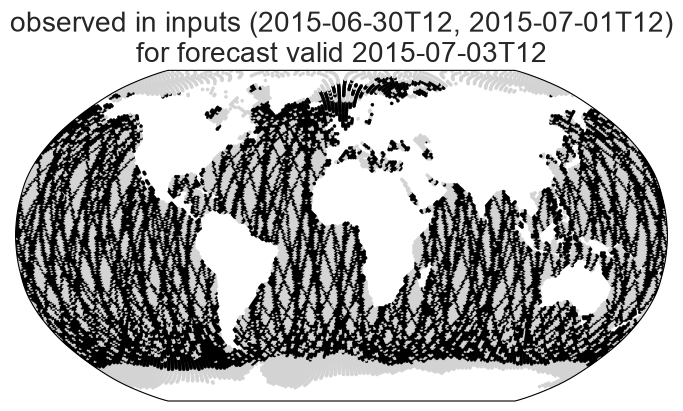

In [33]:
fig, ax = plt.subplots(figsize=(7, 4), subplot_kw={"projection": ccrs.Robinson()})
ax.scatter(
    ads.longitude,
    ads.latitude,
    c=has_obs.any_mission.where(ds.mask).values,
    cmap=ListedColormap(["lightgray", "black"]),
    vmin=0,
    vmax=1,
    transform=ccrs.PlateCarree(),
    s=5,
)
ax.set(
    title=f"observed in inputs ({str(input_times[0])[:13]}, {str(input_times[1])[:13]})"
    f"\nfor forecast valid {str(valid_time)[:13]}"
)

In [35]:
avg = open_anemoi_zarr("anemoi-hpx6-24h/dataset.zarr", array_name="mean")
std = open_anemoi_zarr("anemoi-hpx6-24h/dataset.zarr", array_name="stdev")

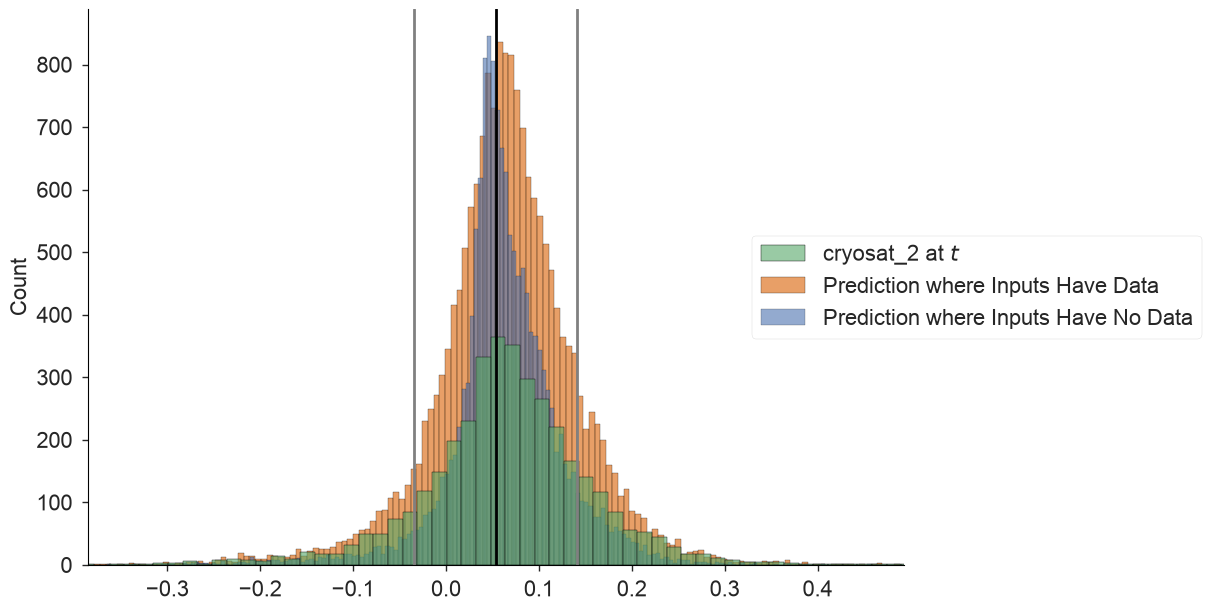

In [65]:
fig, ax = plt.subplots(figsize=(12, 6))
for mission in ["cryosat_2"]:
    vname = f"sla_filtered_{mission}"
    xda = ds[vname].isel(time=0)
    sns.histplot(
        xda.where(~np.isnan(xda)),
        ax=ax,
        label=f"{mission} at $t$",
        alpha=.6,
    )
    ax.axvline(x=avg[vname], color="black")
    ax.axvline(x=avg[vname] + std[vname], color="gray")
    ax.axvline(x=avg[vname] - std[vname], color="gray")
for ff, lbl in zip(
    [has_obs["any_mission"], ~has_obs["any_mission"]],
    ["Inputs Have Data", "Inputs Have No Data"],
):
    sns.histplot(
        ds["sla"].isel(time=1).where(ds["mask"]).where(ff),
        ax=ax,
        label=f"Prediction where {lbl}",
        alpha=.6,
        zorder=0,
    ) 
factor = 5
ax.set(xlim=[-factor*std[vname]+avg[vname], factor*std[vname]+avg[vname]])
ax.legend(bbox_to_anchor=(.8, .5), loc="center left")